<a href="https://colab.research.google.com/github/mohammedsajib/Bank-Marketing-Subscription-Prediction/blob/main/Fake_News_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
import kagglehub
import pandas as pd
from google.colab import files
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Download latest version
path = kagglehub.dataset_download("saurabhshahane/fake-news-classification")

print("Path to dataset files:", path)


path = "/kaggle/input/fake-news-classification"

print(os.listdir(path))

Using Colab cache for faster access to the 'fake-news-classification' dataset.
Path to dataset files: /kaggle/input/fake-news-classification
['WELFake_Dataset.csv']


In [35]:
path = "/kaggle/input/fake-news-classification/WELFake_Dataset.csv"

df = pd.read_csv(path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (72134, 4)


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [36]:
df.columns.tolist()

['Unnamed: 0', 'title', 'text', 'label']

In [37]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


In [38]:
df.isnull().sum()

,0
Unnamed: 0,0
title,558
text,39
label,0


In [39]:
df.duplicated().sum()

np.int64(0)

In [40]:
df['label'].value_counts()

,count
label,
1,37106
0,35028


In [41]:
df = df.dropna(subset=["title", "text"])


In [42]:
df

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1
5,5,About Time! Christian Group Sues Amazon and SP...,All we can say on this one is it s about time ...,1
...,...,...,...,...
72129,72129,Russians steal research on Trump in hack of U....,WASHINGTON (Reuters) - Hackers believed to be ...,0
72130,72130,WATCH: Giuliani Demands That Democrats Apolog...,"You know, because in fantasyland Republicans n...",1
72131,72131,Migrants Refuse To Leave Train At Refugee Camp...,Migrants Refuse To Leave Train At Refugee Camp...,0
72132,72132,Trump tussle gives unpopular Mexican leader mu...,MEXICO CITY (Reuters) - Donald Trump’s combati...,0


In [43]:
df = df.reset_index(drop=True)

In [44]:
df.shape

(71537, 4)

In [45]:
df.isnull().sum()

,0
Unnamed: 0,0
title,0
text,0
label,0


In [46]:
df.duplicated().sum()

np.int64(0)

In [47]:
df = df.drop_duplicates().reset_index(drop=True)

In [48]:
df.shape

(71537, 4)

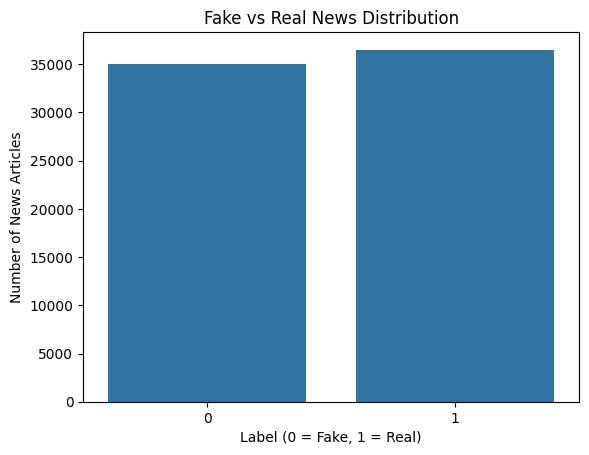

In [49]:
sns.countplot(data=df, x="label")
plt.title("Fake vs Real News Distribution")
plt.xlabel("Label (0 = Fake, 1 = Real)")
plt.ylabel("Number of News Articles")
plt.show()

In [50]:
df["content"] = (
    df["title"].fillna("").astype(str) + " " +
    df["text"].fillna("").astype(str)
)

# Keep only required columns
df = df[["content", "label"]]

print(df.head())
print("\nDataset shape:", df.shape)

                                             content  label
0  LAW ENFORCEMENT ON HIGH ALERT Following Threat...      1
1  UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...      1
2  Bobby Jindal, raised Hindu, uses story of Chri...      0
3  SATAN 2: Russia unvelis an image of its terrif...      1
4  About Time! Christian Group Sues Amazon and SP...      1

Dataset shape: (71537, 2)


In [51]:
X = df['content']
y = df['label']


In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y

)

In [53]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 57229
Testing samples: 14308


In [54]:
tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    dtype="float32"
)

In [55]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


In [56]:
print("Train matrix:", X_train_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)

Train matrix: (57229, 50000)
Test matrix: (14308, 50000)


In [57]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [58]:
y_pred = model.predict(X_test_tfidf)

In [59]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9538719597428013

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95      7006
           1       0.95      0.96      0.96      7302

    accuracy                           0.95     14308
   macro avg       0.95      0.95      0.95     14308
weighted avg       0.95      0.95      0.95     14308



Confusion Matrix:
[[6618  388]
 [ 272 7030]]


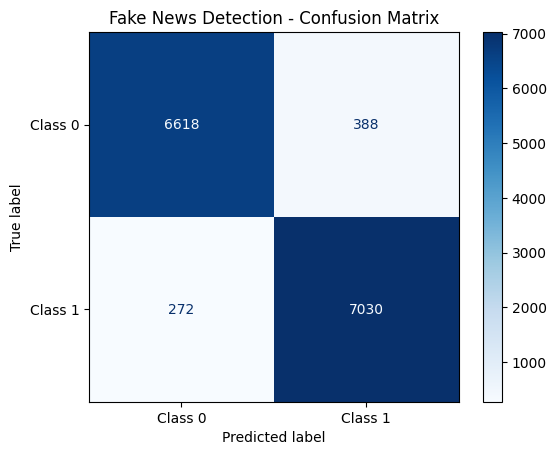

In [61]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()

In [62]:
def predict_news(title, text):
    content = title + " " + text
    features = tfidf.transform([content])

    prediction = model.predict(features)[0]
    probability = model.predict_proba(features)[0].max()

    print("Predicted label:", prediction)
    print(f"Model confidence: {probability:.2%}")

    return prediction

predict_news(
    "Scientists announce a new discovery",
    "Researchers published a report describing their latest scientific findings."
)

Predicted label: 1
Model confidence: 74.65%


np.int64(1)

In [63]:
import joblib

joblib.dump(model, "fake_news_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")

Model saved successfully!


In [64]:
from google.colab import files

files.download("fake_news_model.pkl")
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>